# Skin Cancer Dataset: Metadata and Exploration

This notebook explores the **Skin Cancer** clinical image dataset from Kaggle (`mahdavi1202/skin-cancer`). Below is an overview of the dataset structure and properties:

* **Total Images**: 2,298 clinical images.
* **Image Dimensions**: Typically high resolution (e.g., $1089 \times 1089$ pixels).
* **Primary Goal**: Multi-class classification of skin lesions.

### Diagnosis Classes
We have 6 distinct categories of skin lesions in this dataset:
1. **ACK**: Actinic Keratosis
2. **BCC**: Basal Cell Carcinoma
3. **MEL**: Melanoma
4. **NEV**: Nevus
5. **SCC**: Squamous Cell Carcinoma
6. **SEK**: Seborrheic Keratosis

### Metadata Features
The metadata contains patient information such as `patient_id`, `age`, `smoke`, `drink`, and other clinical signs like `bleed` to assist with classification and analysis.

In [ ]:
import os, glob, pandas as pd
import kagglehub

IMG_ROOT = kagglehub.dataset_download("mahdavi1202/skin-cancer")
img_df = pd.read_csv(os.path.join(IMG_ROOT, "metadata.csv"))

path_map = {os.path.basename(p): p for p in glob.glob(f"{IMG_ROOT}/**/*.png", recursive=True)}
img_df["path"] = img_df["img_id"].map(path_map)
print(len(path_map), "images found |", img_df["path"].isna().sum(), "missing")
img_df[["img_id", "diagnostic", "path"]].head()

100%|██████████| 3.35G/3.35G [00:36<00:00, 97.7MB/s]

Extracting files...


2298 images found | 0 missing


,img_id,diagnostic,path
0,PAT_1516_1765_530.png,NEV,/root/.cache/kagglehub/datasets/mahdavi1202/sk...
1,PAT_46_881_939.png,BCC,/root/.cache/kagglehub/datasets/mahdavi1202/sk...
2,PAT_1545_1867_547.png,ACK,/root/.cache/kagglehub/datasets/mahdavi1202/sk...
3,PAT_1989_4061_934.png,ACK,/root/.cache/kagglehub/datasets/mahdavi1202/sk...
4,PAT_684_1302_588.png,BCC,/root/.cache/kagglehub/datasets/mahdavi1202/sk...


(1089, 1089)


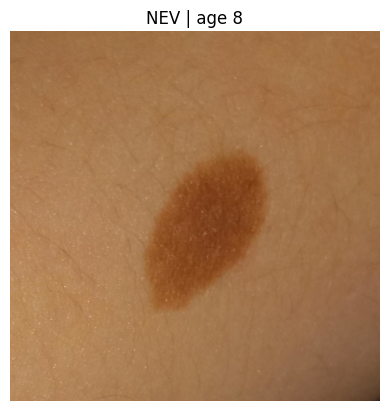

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

sample = img_df.iloc[0]
pic = Image.open(sample["path"]).convert("RGB")
plt.imshow(pic); plt.title(f'{sample["diagnostic"]} | age {sample["age"]}'); plt.axis("off")
print(pic.size)

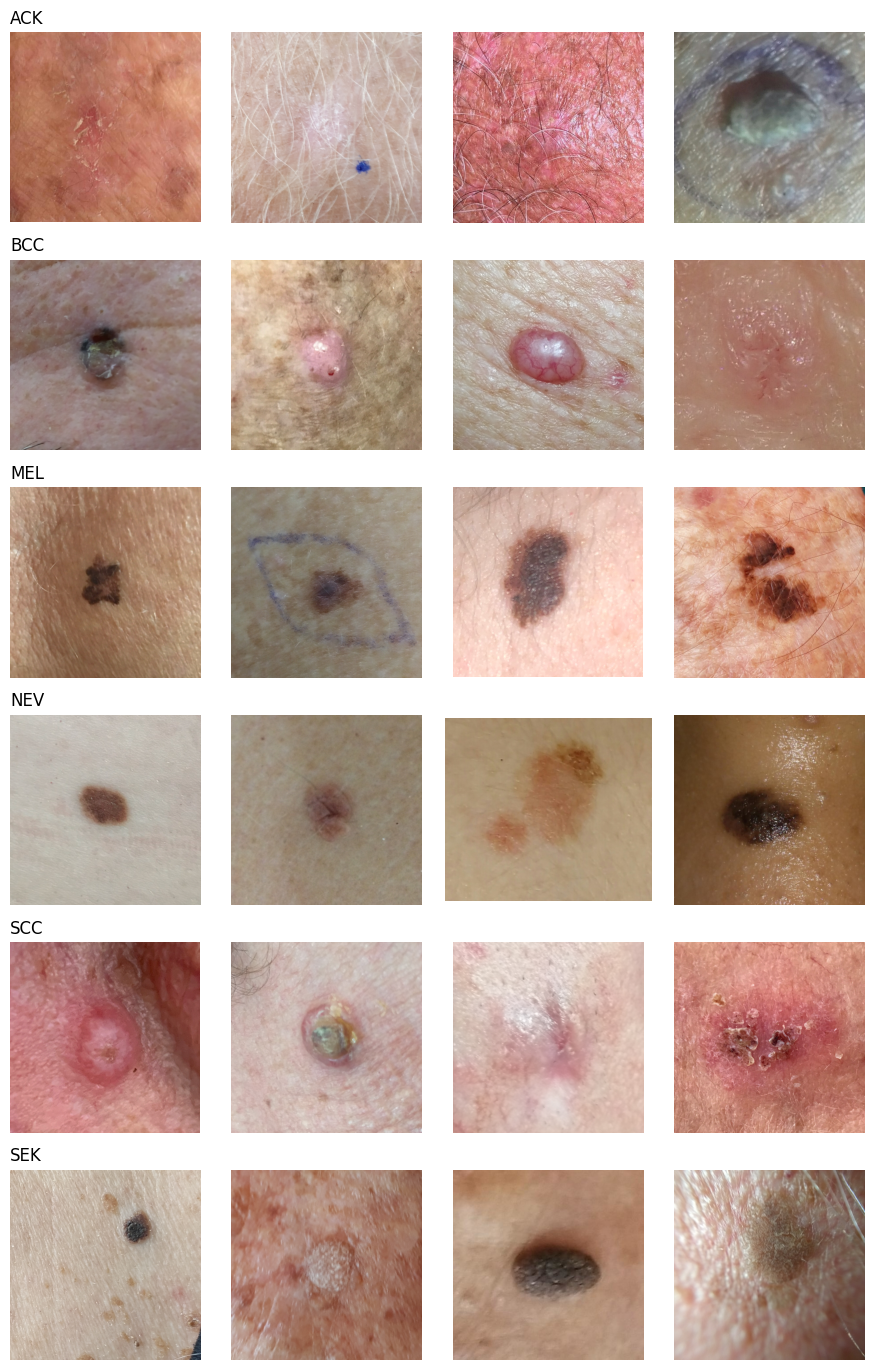

In [ ]:
LESION_CLASSES = sorted(img_df["diagnostic"].unique())
fig, axes = plt.subplots(len(LESION_CLASSES), 4, figsize=(9, 2.3 * len(LESION_CLASSES)))
for r, cls in enumerate(LESION_CLASSES):
    picks = img_df[img_df["diagnostic"] == cls].sample(4, random_state=0)["path"]
    for c, p in enumerate(picks):
        axes[r, c].imshow(Image.open(p).convert("RGB")); axes[r, c].axis("off")
    axes[r, 0].set_title(cls, loc="left")
plt.tight_layout(); plt.show()

In [ ]:
!pip install -q kagglehub

import os, glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub

IMG_ROOT = kagglehub.dataset_download("mahdavi1202/skin-cancer")
print("Downloaded to:", IMG_ROOT)

Using Colab cache for faster access to the 'skin-cancer' dataset.
Downloaded to: /kaggle/input/skin-cancer


In [ ]:
df = pd.read_csv(os.path.join(IMG_ROOT, "metadata.csv"))

# find every .png inside the dataset folders
path_map = {os.path.basename(p): p for p in glob.glob(f"{IMG_ROOT}/**/*.png", recursive=True)}
df["path"] = df["img_id"].map(path_map)

print(len(path_map), "images found |", df["path"].isna().sum(), "missing")
df = df.dropna(subset=["path"]).reset_index(drop=True)

df[["img_id", "patient_id", "diagnostic", "path"]].head()

2298 images found | 0 missing


,img_id,patient_id,diagnostic,path
0,PAT_1516_1765_530.png,PAT_1516,NEV,/kaggle/input/skin-cancer/imgs_part_3/imgs_par...
1,PAT_46_881_939.png,PAT_46,BCC,/kaggle/input/skin-cancer/imgs_part_1/imgs_par...
2,PAT_1545_1867_547.png,PAT_1545,ACK,/kaggle/input/skin-cancer/imgs_part_3/imgs_par...
3,PAT_1989_4061_934.png,PAT_1989,ACK,/kaggle/input/skin-cancer/imgs_part_3/imgs_par...
4,PAT_684_1302_588.png,PAT_684,BCC,/kaggle/input/skin-cancer/imgs_part_2/imgs_par...


diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64


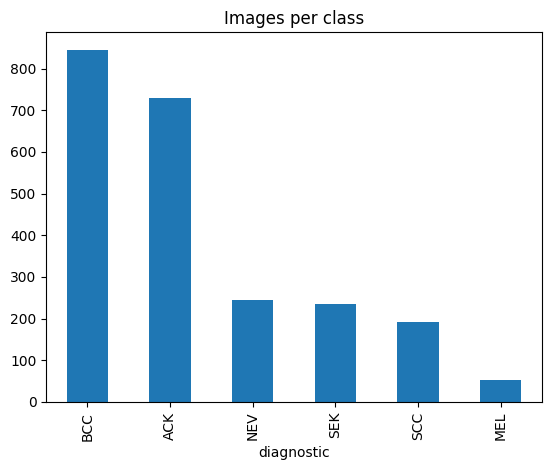

In [ ]:
print(df["diagnostic"].value_counts())

df["diagnostic"].value_counts().plot(kind="bar", title="Images per class")
plt.show()

In [ ]:
sizes = [Image.open(p).size for p in df["path"].sample(200, random_state=0)]
w, h = zip(*sizes)
print(f"width: {min(w)}–{max(w)} | height: {min(h)}–{max(h)}")
print("mode of first image:", Image.open(df["path"][0]).mode)   # RGB or RGBA

width: 235–2683 | height: 235–2683
mode of first image: RGB


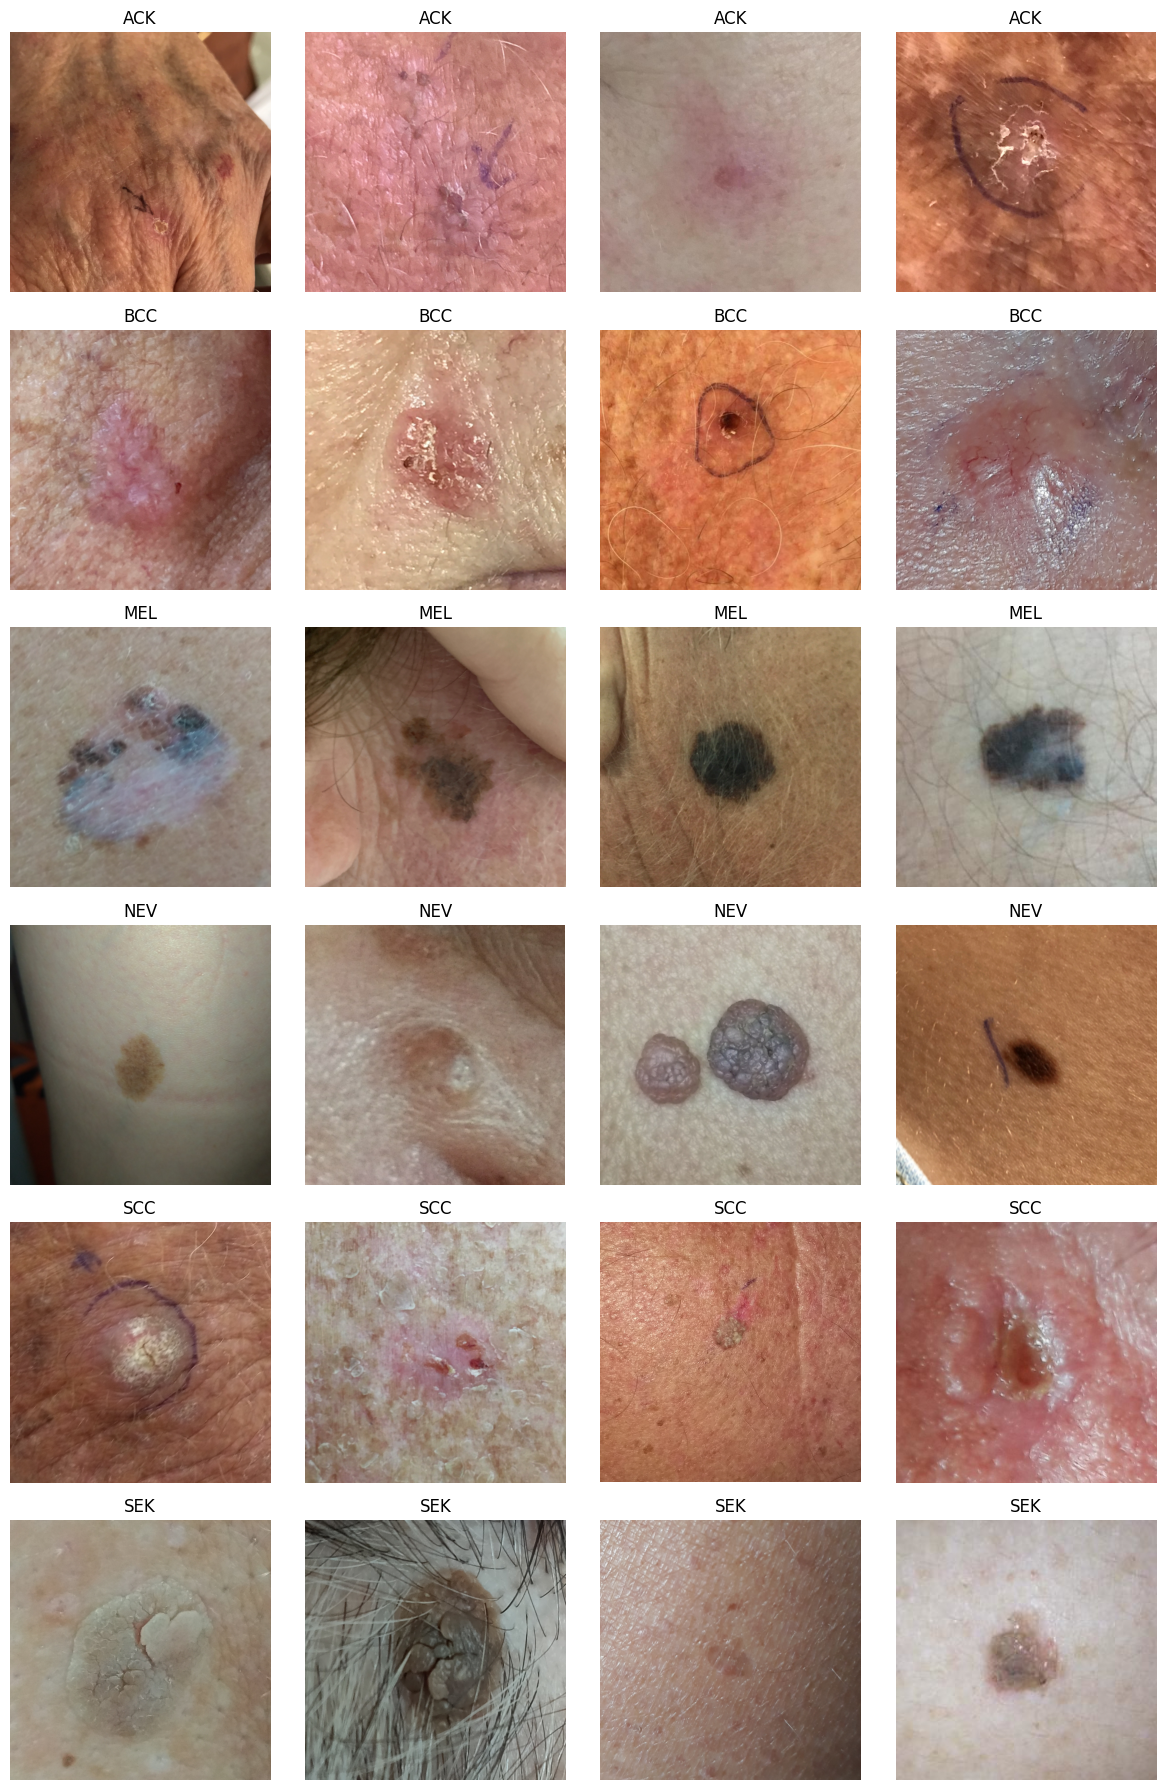

In [ ]:
classes = sorted(df["diagnostic"].unique())
fig, axes = plt.subplots(len(classes), 4, figsize=(12, 3 * len(classes)))

for r, c in enumerate(classes):
    samples = df[df["diagnostic"] == c].sample(4, random_state=1)
    for k, p in enumerate(samples["path"]):
        axes[r, k].imshow(Image.open(p).convert("RGB"))
        axes[r, k].set_title(c)
        axes[r, k].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from google.colab import drive

drive.mount("/content/drive")
OUT_DIR = "/content/drive/MyDrive/skin_normalized"   # use "/content/skin_normalized" for faster, temporary storage
os.makedirs(OUT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def get_stats(img_bgr):
    L = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)[..., 0].astype(np.float32)
    S = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[..., 1].astype(np.float32)
    return L.mean(), L.std(), S.mean()

stats = []
for p in tqdm(df["path"], desc="Measuring"):
    img = cv2.imread(p, cv2.IMREAD_COLOR)        # drops alpha channel if present
    stats.append(get_stats(img))

df[["brightness", "contrast", "saturation"]] = np.array(stats)
df[["brightness", "contrast", "saturation"]].describe().round(1)

Measuring:   0%|          | 0/2298 [00:00<?, ?it/s]

,brightness,contrast,saturation
count,2298.0,2298.0,2298.0
mean,149.5,25.0,80.3
std,22.0,9.1,35.1
min,72.4,5.5,8.0
25%,135.3,18.4,51.7
50%,149.5,23.4,77.7
75%,164.1,29.9,106.4
max,223.9,67.1,188.4


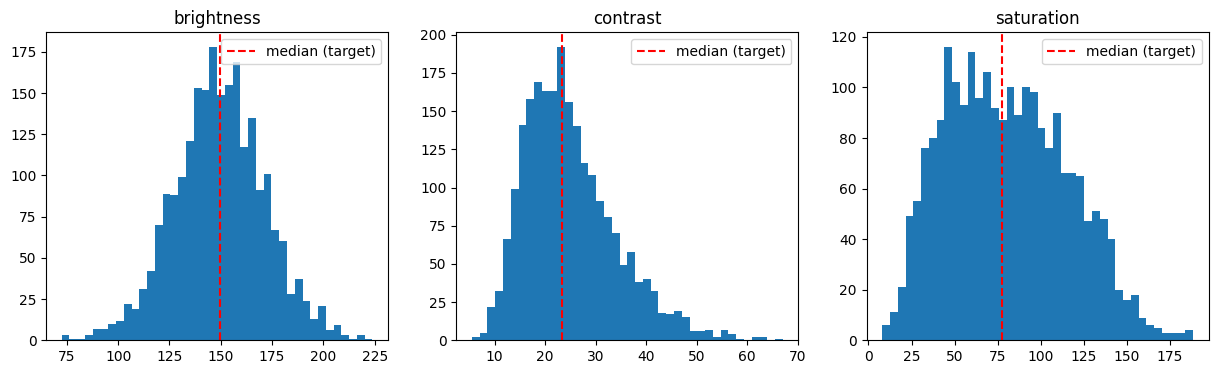

Target → brightness 149.5 | contrast 23.4 | saturation 77.7


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["brightness", "contrast", "saturation"]):
    ax.hist(df[col], bins=40)
    ax.axvline(df[col].median(), color="r", ls="--", label="median (target)")
    ax.set_title(col); ax.legend()
plt.show()

# Target = dataset median (robust to the very dark / overexposed outliers)
T_BRIGHT = df["brightness"].median()
T_CONTR  = df["contrast"].median()
T_SAT    = df["saturation"].median()
print(f"Target → brightness {T_BRIGHT:.1f} | contrast {T_CONTR:.1f} | saturation {T_SAT:.1f}")

In [ ]:
def normalize_image(img_bgr, t_bright, t_contr, t_sat, max_scale=2.0):
    # 1) Saturation: scale S so its mean = target
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
    s_scale = np.clip(t_sat / (hsv[..., 1].mean() + 1e-6), 1/max_scale, max_scale)
    hsv[..., 1] = np.clip(hsv[..., 1] * s_scale, 0, 255)
    img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

    # 2) Brightness + contrast: shift/scale L so mean = target, std = target
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB).astype(np.float32)
    L = lab[..., 0]
    c_scale = np.clip(t_contr / (L.std() + 1e-6), 1/max_scale, max_scale)
    lab[..., 0] = np.clip((L - L.mean()) * c_scale + t_bright, 0, 255)
    return cv2.cvtColor(lab.astype(np.uint8), cv2.COLOR_LAB2BGR)

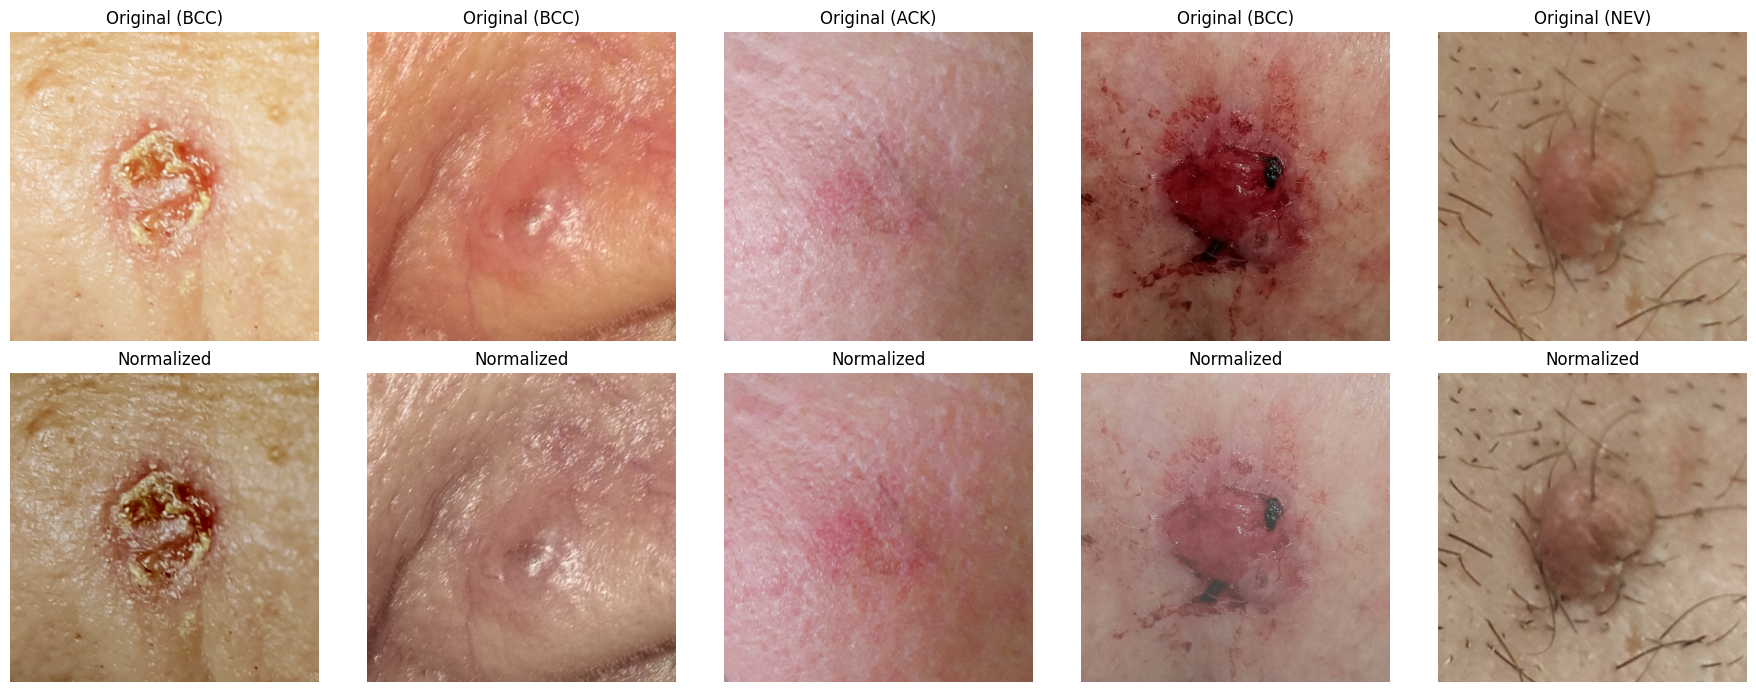

In [ ]:
samples = df.sample(5, random_state=3)
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for i, (_, row) in enumerate(samples.iterrows()):
    img = cv2.imread(row["path"], cv2.IMREAD_COLOR)
    out = normalize_image(img, T_BRIGHT, T_CONTR, T_SAT)
    axes[0, i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0, i].set_title(f"Original ({row['diagnostic']})")
    axes[1, i].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); axes[1, i].set_title("Normalized")
    for a in axes[:, i]: a.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
new_paths, new_stats = [], []
for _, row in tqdm(df.iterrows(), total=len(df), desc="Normalizing"):
    img = cv2.imread(row["path"], cv2.IMREAD_COLOR)
    out = normalize_image(img, T_BRIGHT, T_CONTR, T_SAT)

    cls_dir = os.path.join(OUT_DIR, row["diagnostic"])
    os.makedirs(cls_dir, exist_ok=True)
    out_path = os.path.join(cls_dir, row["img_id"])
    cv2.imwrite(out_path, out)                  # PNG = lossless

    new_paths.append(out_path)
    new_stats.append(get_stats(out))

df["norm_path"] = new_paths
df[["n_brightness", "n_contrast", "n_saturation"]] = np.array(new_stats)
df.to_csv(os.path.join(OUT_DIR, "metadata_normalized.csv"), index=False)
print("Saved", len(df), "images to", OUT_DIR)

Normalizing:   0%|          | 0/2298 [00:00<?, ?it/s]

Saved 2298 images to /content/drive/MyDrive/skin_normalized


In [ ]:
compare = pd.DataFrame({
    "before_std": df[["brightness", "contrast", "saturation"]].std().values,
    "after_std":  df[["n_brightness", "n_contrast", "n_saturation"]].std().values,
}, index=["brightness", "contrast", "saturation"]).round(2)
print(compare)

            before_std  after_std
brightness   21.969999       0.06
contrast      9.070000       0.81
saturation   35.130001      11.56


Augmentation

In [ ]:
import os, glob, shutil
from PIL import Image
from tqdm.auto import tqdm
from torchvision import transforms
import matplotlib.pyplot as plt

IN_DIR  = "/content/drive/MyDrive/skin_normalized"   # normalized images, one folder per class
OUT_DIR = "/content/drive/MyDrive/skin_augmented"
os.makedirs(OUT_DIR, exist_ok=True)

CLASSES = sorted(d for d in os.listdir(IN_DIR) if os.path.isdir(os.path.join(IN_DIR, d)))
images = {c: sorted(glob.glob(os.path.join(IN_DIR, c, "*.png"))) for c in CLASSES}
for c in CLASSES:
    print(f"{c}: {len(images[c])}")

ACK: 730
BCC: 845
MEL: 52
NEV: 244
SCC: 192
SEK: 235


In [ ]:
import cv2, random
import numpy as np

TARGET = max(len(v) for v in images.values())
MAX_PER_IMG = 10
IMG_SIZE = 224

def augment(img):
    """Geometric augmentation only: no brightness / contrast / saturation change."""
    img = np.array(img)                                   # RGB uint8
    # 1. flips
    if random.random() < 0.5: img = np.fliplr(img)
    if random.random() < 0.5: img = np.flipud(img)
    # 2. 90° rotations (lossless)
    img = np.rot90(img, k=random.randint(0, 3))
    img = np.ascontiguousarray(img)

    # 3. small rotation + zoom + shift + shear, with mirrored borders (no black corners)
    h, w = img.shape[:2]
    angle = random.uniform(-30, 30)
    scale = random.uniform(1.0, 1.2)                      # zoom in only
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
    M[0, 2] += random.uniform(-0.08, 0.08) * w            # shift x
    M[1, 2] += random.uniform(-0.08, 0.08) * h            # shift y
    shear = np.deg2rad(random.uniform(-8, 8))
    M[0, 1] += np.tan(shear)
    img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR,
                         borderMode=cv2.BORDER_REFLECT_101)

    # 4. resize to final size
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return Image.fromarray(img)

In [ ]:
random.seed(42); np.random.seed(42)

for c in CLASSES:
    src = images[c]
    n = len(src)
    out_c = os.path.join(OUT_DIR, c)
    os.makedirs(out_c, exist_ok=True)

    for p in tqdm(src, desc=f"{c} originals", leave=False):
        Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE)).save(os.path.join(out_c, os.path.basename(p)))

    need = max(min(TARGET - n, n * MAX_PER_IMG), 0)
    for i in tqdm(range(need), desc=f"{c} +{need}"):
        p = src[i % n]
        augment(Image.open(p).convert("RGB")).save(os.path.join(out_c, f"aug{i // n}_{os.path.basename(p)}"))

ACK originals:   0%|          | 0/730 [00:00<?, ?it/s]

ACK +115:   0%|          | 0/115 [00:00<?, ?it/s]

BCC originals:   0%|          | 0/845 [00:00<?, ?it/s]

BCC +0: 0it [00:00, ?it/s]

MEL originals:   0%|          | 0/52 [00:00<?, ?it/s]

...

NEV +601:   0%|          | 0/601 [00:00<?, ?it/s]

SCC originals:   0%|          | 0/192 [00:00<?, ?it/s]

SCC +653:   0%|          | 0/653 [00:00<?, ?it/s]

SEK originals:   0%|          | 0/235 [00:00<?, ?it/s]

SEK +610:   0%|          | 0/610 [00:00<?, ?it/s]

In [ ]:
def get_stats(path):
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    L = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)[..., 0].astype(np.float32)
    S = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)[..., 1].astype(np.float32)
    return L.mean(), L.std(), S.mean()

orig = [get_stats(p) for p in glob.glob(f"{OUT_DIR}/*/*.png") if not os.path.basename(p).startswith("aug")][:300]
augd = [get_stats(p) for p in glob.glob(f"{OUT_DIR}/*/aug*.png")][:300]

for name, data in [("original", orig), ("augmented", augd)]:
    b, c, s = np.array(data).T
    print(f"{name:9s} → brightness {b.mean():.1f}±{b.std():.1f} | contrast {c.mean():.1f}±{c.std():.1f} | saturation {s.mean():.1f}±{s.std():.1f}")

original  → brightness 149.1±0.1 | contrast 22.9±1.4 | saturation 77.3±9.7
augmented → brightness 148.2±2.6 | contrast 22.8±2.1 | saturation 73.3±13.1


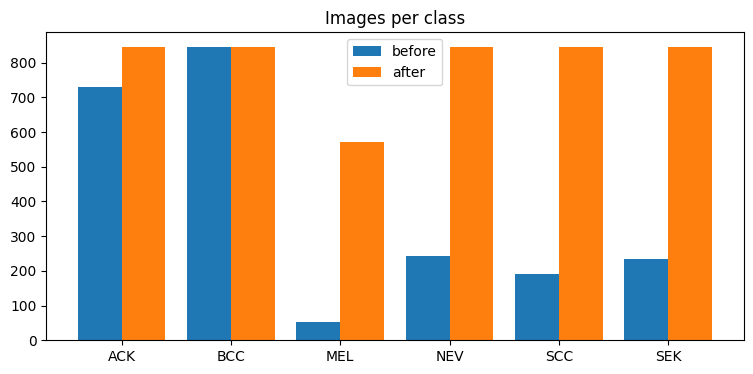

ACK: 730 → 845
BCC: 845 → 845
MEL: 52 → 572
NEV: 244 → 845
SCC: 192 → 845
SEK: 235 → 845


In [ ]:
before = {c: len(images[c]) for c in CLASSES}
after  = {c: len(glob.glob(os.path.join(OUT_DIR, c, "*.png"))) for c in CLASSES}

x = range(len(CLASSES))
plt.figure(figsize=(9, 4))
plt.bar([i - 0.2 for i in x], before.values(), 0.4, label="before")
plt.bar([i + 0.2 for i in x], after.values(), 0.4, label="after")
plt.xticks(x, CLASSES); plt.legend(); plt.title("Images per class"); plt.show()

for c in CLASSES:
    print(f"{c}: {before[c]} → {after[c]}")

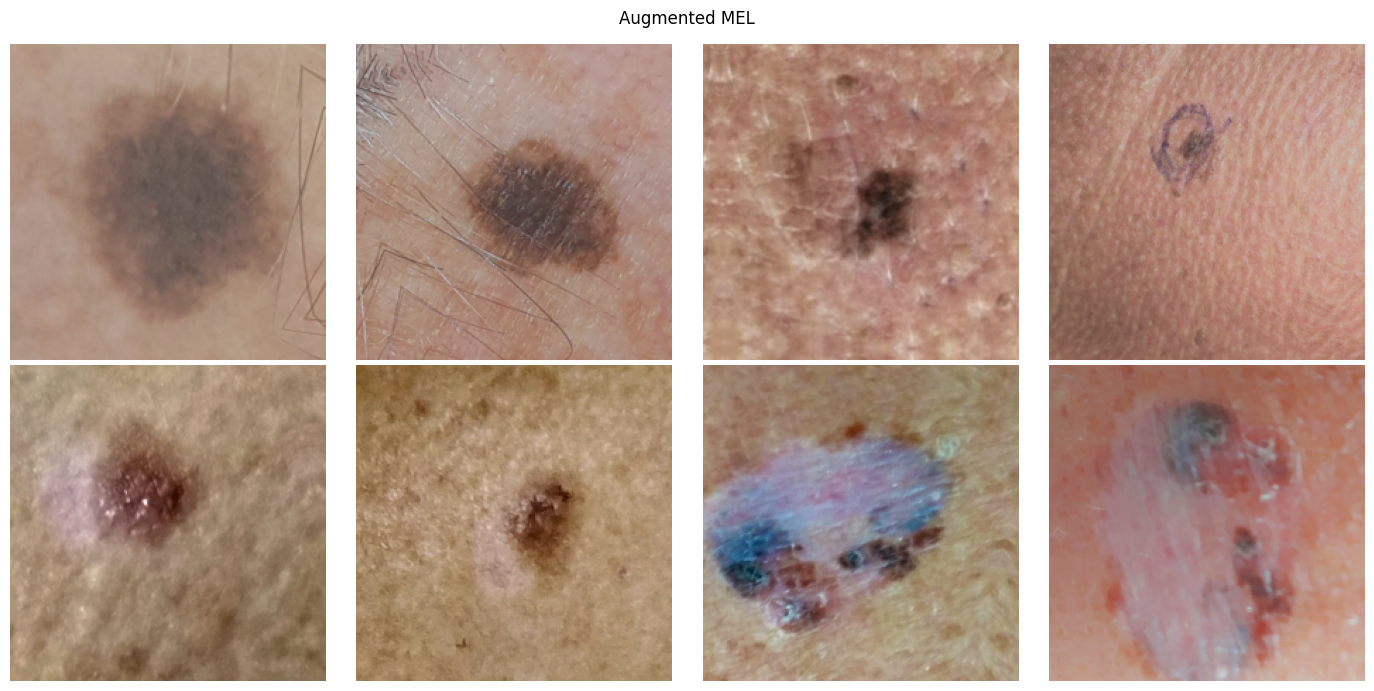

In [ ]:
aug_files = glob.glob(os.path.join(OUT_DIR, "MEL", "aug*.png"))[:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, p in zip(axes.flat, aug_files):
    ax.imshow(Image.open(p)); ax.axis("off")
plt.suptitle("Augmented MEL"); plt.tight_layout(); plt.show()